# Lab 08 — Model Evaluation, Class Imbalance and Model Selection
## Student Activity

### Dataset
**Give Me Some Credit** (`GiveMeSomeCredit-training.csv`)

You are provided with:
- the real dataset;
- code to load it;
- a deliberately weak baseline classifier.

Your task is to investigate the baseline, improve the modelling and evaluation workflow, and justify the decisions you make.

There is **no fixed sequence of implementation cells**. You may add, remove, reorder, and organize cells in any clear and reproducible way.

## 1. Load the dataset

Upload `GiveMeSomeCredit-training.csv` to the notebook working directory and run the cell below.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    classification_report,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

DATA_PATH = Path("GiveMeSomeCredit-training.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "cs-training.csv was not found. Upload it to the notebook working directory."
    )

df = pd.read_csv(DATA_PATH)

# Remove the index-like column normally included with this dataset.
unnamed_cols = [c for c in df.columns if c.lower().startswith("unnamed")]
if unnamed_cols:
    df = df.drop(columns=unnamed_cols)

print("Shape:", df.shape)
display(df.head())

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["SeriousDlqin2yrs"].value_counts())
print(df["SeriousDlqin2yrs"].value_counts(normalize=True).round(4))

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0



Columns:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Target distribution:
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    0.9332
1    0.0668
Name: proportion, dtype: float64


## 2. Deliberately weak baseline

Run the baseline below before starting your own work.

The code runs, but the workflow is intentionally incomplete and should **not** automatically be accepted as the final solution.

Your task is to identify its weaknesses and improve the complete modelling process starting again from the original `df`.

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.9305,0.5317,0.032,0.0603,0.1177,0.6921,0.2282


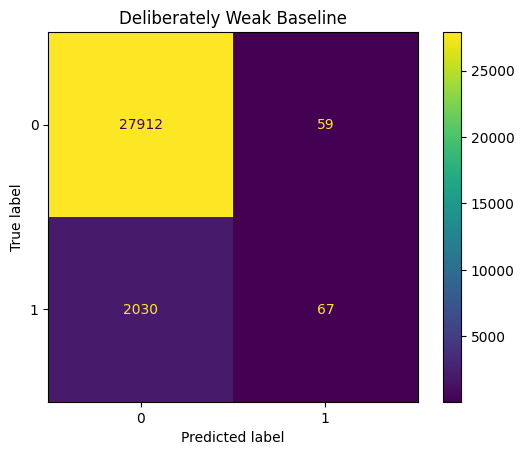

In [3]:
baseline_df = df.dropna().copy()

X_bad = baseline_df.drop(columns="SeriousDlqin2yrs")
y_bad = baseline_df["SeriousDlqin2yrs"]

X_train_bad, X_check_bad, y_train_bad, y_check_bad = train_test_split(
    X_bad,
    y_bad,
    test_size=0.25,
    random_state=RANDOM_STATE
)

baseline = LogisticRegression(
    max_iter=5000,
    random_state=RANDOM_STATE
)

baseline.fit(X_train_bad, y_train_bad)

baseline_prob = baseline.predict_proba(X_check_bad)[:, 1]
baseline_pred = (baseline_prob >= 0.50).astype(int)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_check_bad, baseline_prob
)

baseline_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_check_bad, baseline_pred),
    "Precision": precision_score(y_check_bad, baseline_pred, zero_division=0),
    "Recall": recall_score(y_check_bad, baseline_pred, zero_division=0),
    "F1": f1_score(y_check_bad, baseline_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_check_bad, baseline_pred),
    "ROC-AUC": roc_auc_score(y_check_bad, baseline_prob),
    "PR-AUC": auc(recall_curve, precision_curve)
}])

display(baseline_metrics.round(4))

ConfusionMatrixDisplay.from_predictions(y_check_bad, baseline_pred)
plt.title("Deliberately Weak Baseline")
plt.show()

# 3. Your Task

Starting again from the original `df`, develop a stronger and defensible modelling workflow.

You are free to organize your notebook as you wish, but the following **core requirements are compulsory**.

### Compulsory requirements

1. **Diagnose the problem**
   - inspect the target distribution;
   - inspect missing data;
   - identify the main weaknesses of the supplied baseline.

2. **Protect the final test set**
   - create an appropriate stratified development/final-test split;
   - keep the final test set outside threshold selection, imbalance-method selection, model selection, and hyperparameter tuning.

3. **Use leakage-safe preprocessing**
   - any imputation, scaling, or other data-dependent preprocessing must be fitted using training/development data only;
   - a suitable `Pipeline` is recommended.

4. **Evaluate beyond accuracy**
   - report and interpret Precision, Recall, and F1-score;
   - include at least one additional suitable measure such as MCC, ROC-AUC, or PR-AUC.

5. **Investigate the decision threshold**
   - compare more than one probability threshold;
   - explain how the threshold changes Precision, Recall, and the types of classification errors.

6. **Use at least one class-imbalance strategy**
   - compare at least one justified imbalance-handling method against a standard baseline;
   - examples include class weighting or SMOTE.

7. **Use stratified cross-validation**
   - use a stratified k-fold validation procedure;
   - summarize the validation results rather than relying only on one split.

8. **Perform hyperparameter tuning**
   - use `GridSearchCV` or another justified validation-based tuning method;
   - tune at least one relevant hyperparameter such as Logistic Regression `C`.

9. **Evaluate the selected final workflow**
   - after all modelling choices are fixed, evaluate the selected workflow once on the untouched final test set.

10. **Justify the final model**
    - explain which final model/configuration you would deploy and support your decision using experimental evidence.

## 4. Techniques you may consider

The following techniques may help, but they are **not all compulsory**:

- `class_weight="balanced"`
- SMOTE
- ROC curve and ROC-AUC
- Precision–Recall curve and PR-AUC
- alternative decision thresholds
- additional preprocessing or transformations
- additional Logistic Regression hyperparameters
- additional classifiers for fair comparison

Do not include a technique only because it appears in this list.  
If you decide not to use a suggested technique, explain why that decision is reasonable.

# 5. Questions to answer

Use the evidence generated in your own notebook to answer the following.

### Q1
What were the main weaknesses of the supplied baseline? Which weakness most affected the reliability of the evaluation?

### Q2
Which evaluation measures did you use, and why are they appropriate for this problem? Why is accuracy alone insufficient?

### Q3
Which class-imbalance method did you use? Why did you choose it? If you chose not to use another suggested method such as SMOTE or class weighting, justify that decision.

### Q4
Did you change the default decision threshold of 0.50? Explain your decision using the observed Precision–Recall trade-off.

### Q5
How did you perform validation and hyperparameter selection while ensuring that the final test set did not influence model-selection decisions?

### Q6
Which final model/configuration would you deploy? Support your choice using development/CV results and the untouched final test performance.

# 6. Your Work

Add as many code and Markdown cells as needed below.

Your notebook should be:
- clear;
- reproducible;
- leakage-safe;
- supported by appropriate tables, plots, metrics, and validation results.

In [4]:
# Begin your analysis here.